# Notebook 1.1 — Exploratory Data Analysis: NASA CMAPSS (FD002)

**Dataset:** NASA C-MAPSS Turbofan Engine Degradation Simulation Dataset


## 0 · Imports and setup

In [1]:
import sys
from pathlib import Path

# Add project root to path so we can import from src/
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from src.utils.config import (
    DATA_RAW, COL_NAMES, INFORMATIVE_SENSORS,
    SENSOR_DESC, DROP_SENSORS, RUL_CLIP, OUT_FIGURES
)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
print('Setup complete.')
print(f'Looking for data in: {DATA_RAW}')
print(f'Files found: {len(list(DATA_RAW.glob("*.txt")))} .txt files')

Setup complete.
Looking for data in: C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\data\raw\CMAPSS
Files found: 13 .txt files


## 1 · Load raw data

In [2]:
def load_train(subset):
    """Load training split and compute RUL label for each row."""
    path = DATA_RAW / f'train_{subset}.txt'
    df   = pd.read_csv(path, sep=r'\s+', header=None, names=COL_NAMES)
    # RUL = cycles remaining = max_cycle_for_this_unit - current_cycle
    max_c = df.groupby('unit_id')['cycle'].max().rename('max_cycle')
    df    = df.merge(max_c, on='unit_id')
    df['RUL'] = df['max_cycle'] - df['cycle']   # raw, not yet clipped
    df.drop(columns='max_cycle', inplace=True)
    df['subset'] = subset
    return df

trains = {s: load_train(s) for s in SUBSETS}

# Quick look at FD001
print('FD001 shape:', trains['FD001'].shape)
print('\nFirst 3 rows:')
trains['FD001'].head(3)

FD001 shape: (20631, 28)

First 3 rows:


,unit_id,cycle,op_1,op_2,op_3,s_1,s_2,s_3,s_4,s_5,...,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,RUL,subset
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,FD001
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,FD001
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,FD001


## 2 · Dataset statistics

In [3]:
print(f"{'Subset':<8} {'Units':>6} {'Total rows':>12} {'Min life':>10} {'Max life':>10} {'Mean life':>11}")
print('-' * 62)
for s in SUBSETS:
    df = trains[s]
    ul = df.groupby('unit_id')['cycle'].max()
    print(f"{s:<8} {ul.count():>6} {len(df):>12,} {ul.min():>10} "
          f"{ul.max():>10} {ul.mean():>11.1f}")

print('\nNote: FD001 & FD003 = 1 operating condition | FD002 & FD004 = 6 operating conditions')
print('      FD001 & FD002 = 1 fault mode          | FD003 & FD004 = 2 fault modes')

Subset    Units   Total rows   Min life   Max life   Mean life
--------------------------------------------------------------
FD001       100       20,631        128        362       206.3
FD002       260       53,759        128        378       206.8
FD003       100       24,720        145        525       247.2
FD004       249       61,249        128        543       246.0

Note: FD001 & FD003 = 1 operating condition | FD002 & FD004 = 6 operating conditions
      FD001 & FD002 = 1 fault mode          | FD003 & FD004 = 2 fault modes


## 3 · Engine lifetime distribution

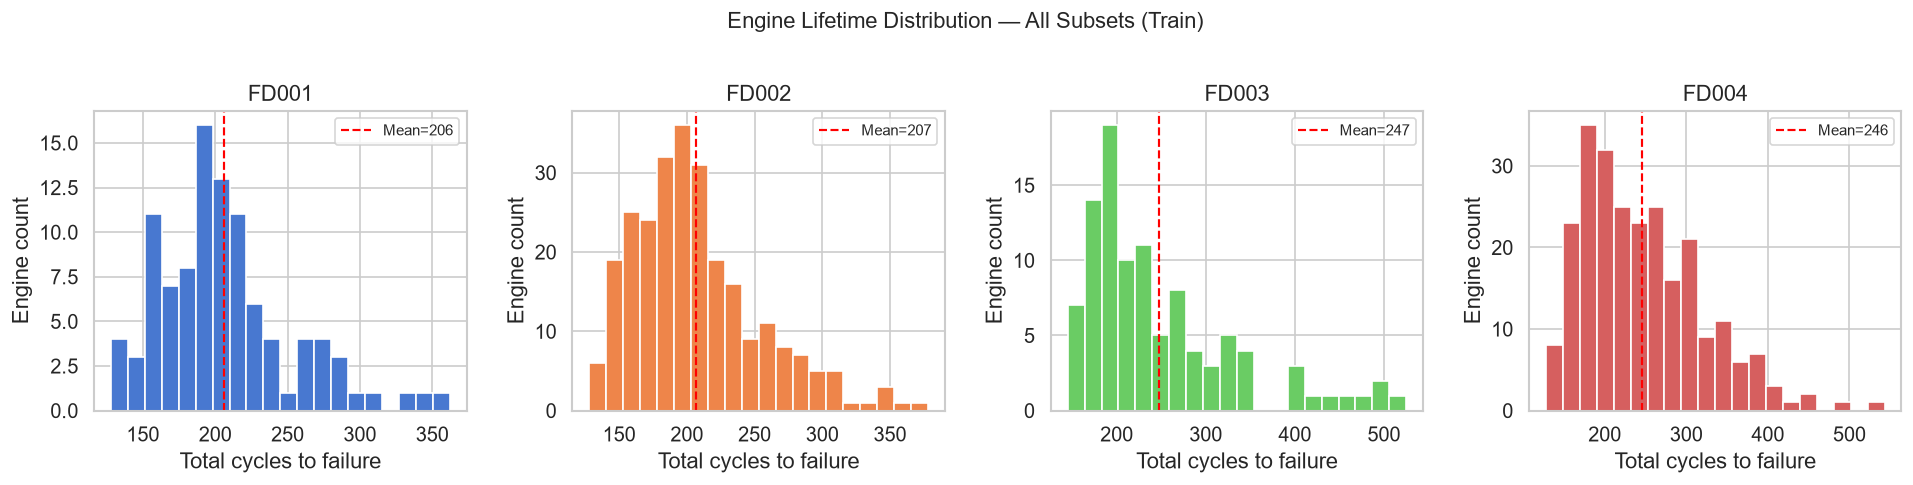

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
colors = sns.color_palette('muted', 4)

for ax, s, c in zip(axes, SUBSETS, colors):
    ul = trains[s].groupby('unit_id')['cycle'].max()
    ax.hist(ul, bins=20, color=c, edgecolor='white')
    ax.axvline(ul.mean(), color='red', linestyle='--',
               linewidth=1.3, label=f'Mean={ul.mean():.0f}')
    ax.set_title(s)
    ax.set_xlabel('Total cycles to failure')
    ax.set_ylabel('Engine count')
    ax.legend(fontsize=9)

fig.suptitle('Engine Lifetime Distribution — All Subsets (Train)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_01_lifetime_dist.png', bbox_inches='tight')
plt.show()

## 4 · Sensor variance analysis

Some sensors are constant across all cycles — they carry no predictive signal and must be dropped before modelling.

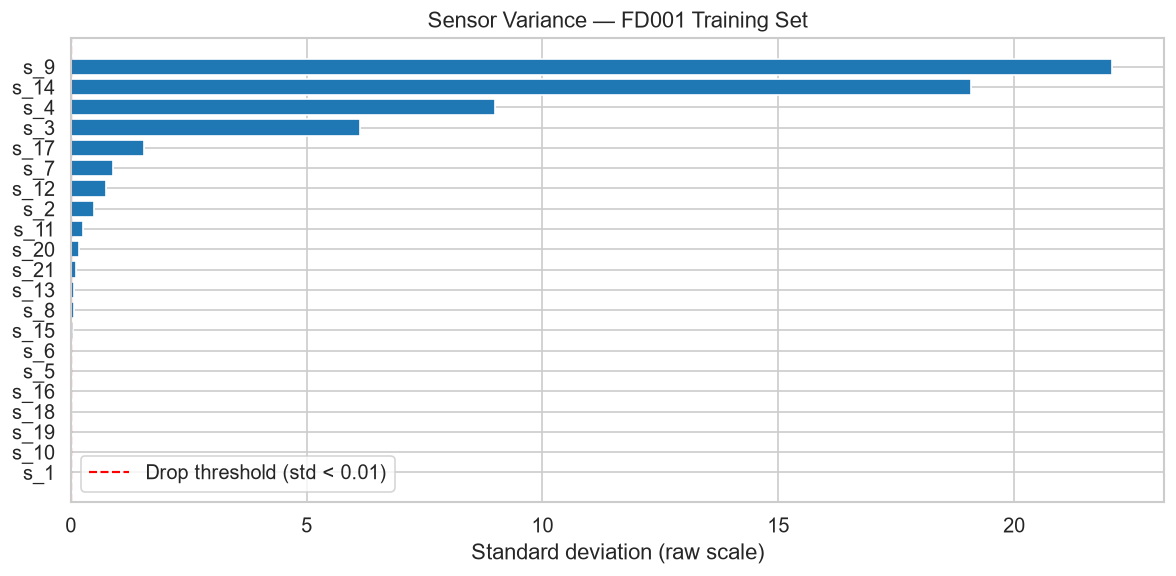

Sensors to DROP  : ['s_1', 's_10', 's_19', 's_18', 's_16', 's_5', 's_6']
Sensors to KEEP  : ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Retained count   : 14 / 21


In [5]:
ALL_SENSORS = [f's_{i}' for i in range(1, 22)]
stds = trains['FD001'][ALL_SENSORS].std().sort_values()
bar_colors = ['#d62728' if v < 0.01 else '#1f77b4' for v in stds.values]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(stds.index, stds.values, color=bar_colors, edgecolor='white')
ax.axvline(0.01, color='red', linestyle='--', linewidth=1.3,
           label='Drop threshold (std < 0.01)')
ax.set_xlabel('Standard deviation (raw scale)')
ax.set_title('Sensor Variance — FD001 Training Set')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_02_sensor_variance.png', bbox_inches='tight')
plt.show()

dropped = stds[stds < 0.01].index.tolist()
print(f'Sensors to DROP  : {dropped}')
print(f'Sensors to KEEP  : {[s for s in ALL_SENSORS if s not in dropped]}')
print(f'Retained count   : {len(ALL_SENSORS) - len(dropped)} / {len(ALL_SENSORS)}')

## 5 · Degradation trajectories

Plot how each informative sensor evolves over an engine's lifetime for 5 sample engines.

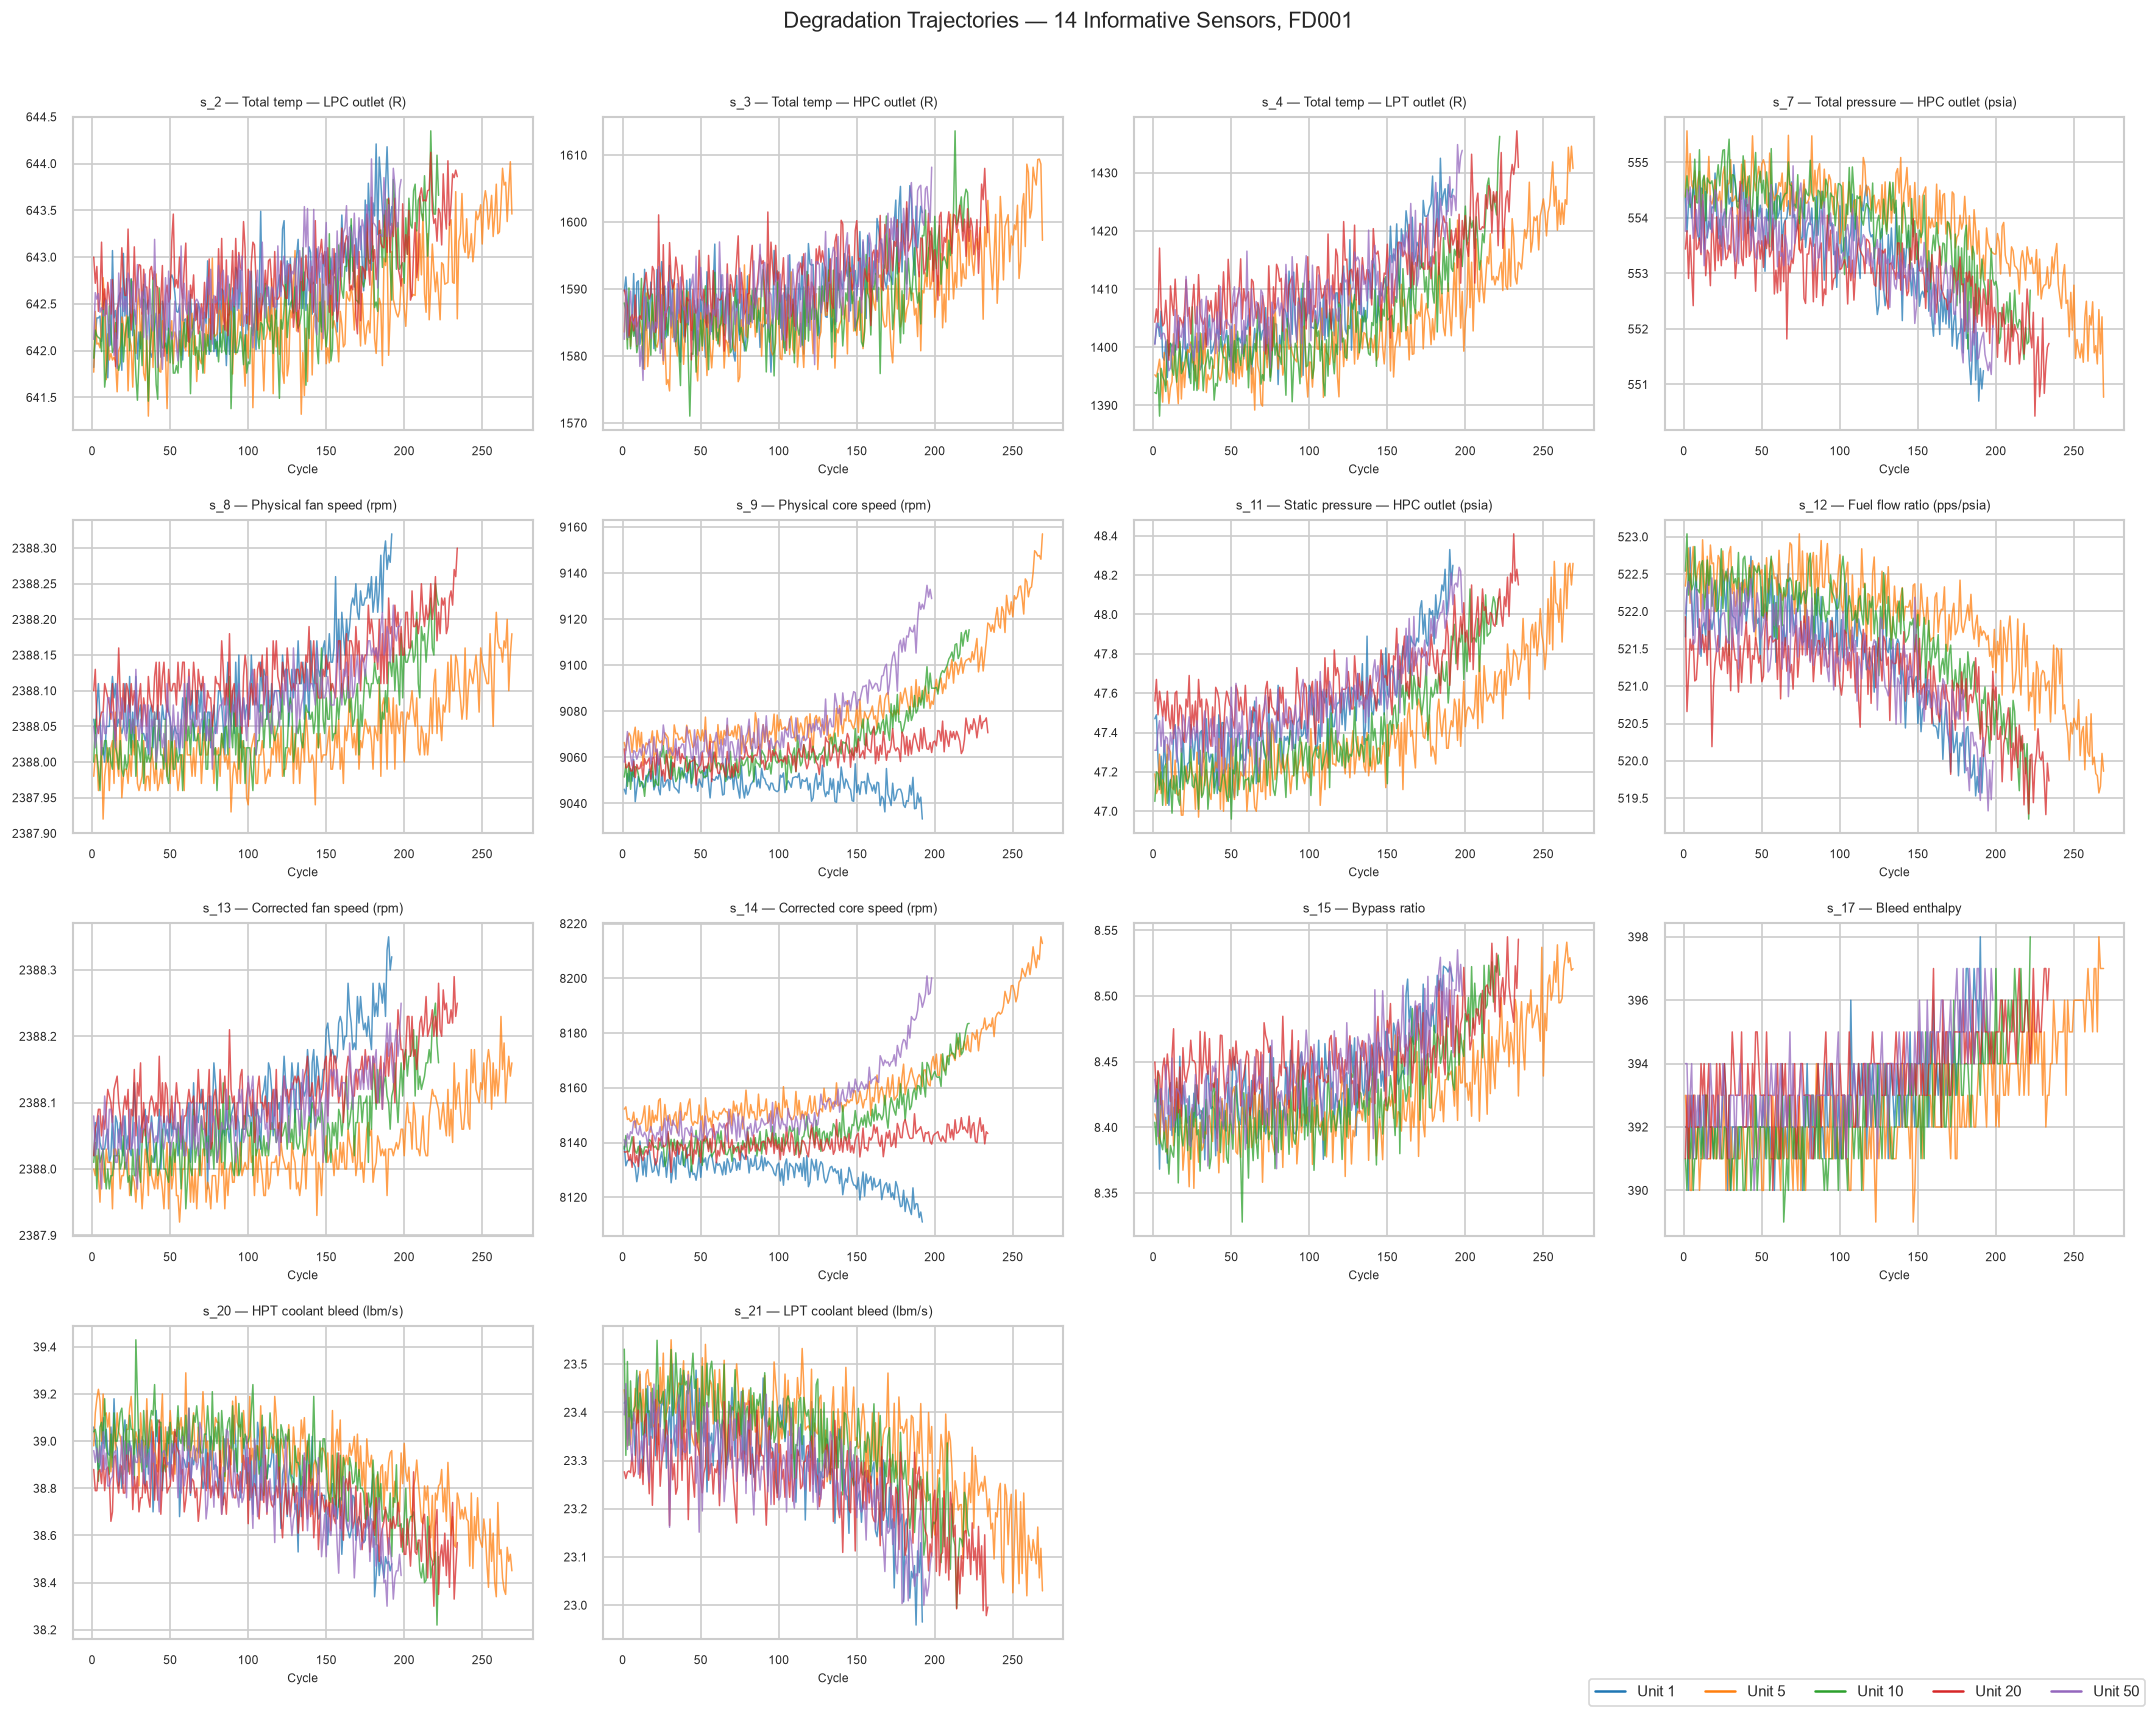

In [6]:
SAMPLE_UNITS = [1, 5, 10, 20, 50]
df1     = trains['FD001']
palette = sns.color_palette('tab10', len(SAMPLE_UNITS))

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for ax, sensor in zip(axes, INFORMATIVE_SENSORS):
    for uid, col in zip(SAMPLE_UNITS, palette):
        u = df1[df1['unit_id'] == uid]
        ax.plot(u['cycle'], u[sensor], color=col,
                alpha=0.75, linewidth=0.9, label=f'Unit {uid}')
    desc = SENSOR_DESC.get(sensor, '')[:35]
    ax.set_title(f'{sensor} — {desc}', fontsize=8)
    ax.set_xlabel('Cycle', fontsize=7)
    ax.tick_params(labelsize=7)

for ax in axes[len(INFORMATIVE_SENSORS):]:
    ax.set_visible(False)

handles = [plt.Line2D([0],[0], color=c, lw=1.5) for c in palette]
fig.legend(handles, [f'Unit {u}' for u in SAMPLE_UNITS],
           loc='lower right', ncol=5, fontsize=9)
fig.suptitle('Degradation Trajectories — 14 Informative Sensors, FD001',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_03_degradation_trajectories.png', bbox_inches='tight')
plt.show()

## 6 · Sensor–RUL correlation heatmap

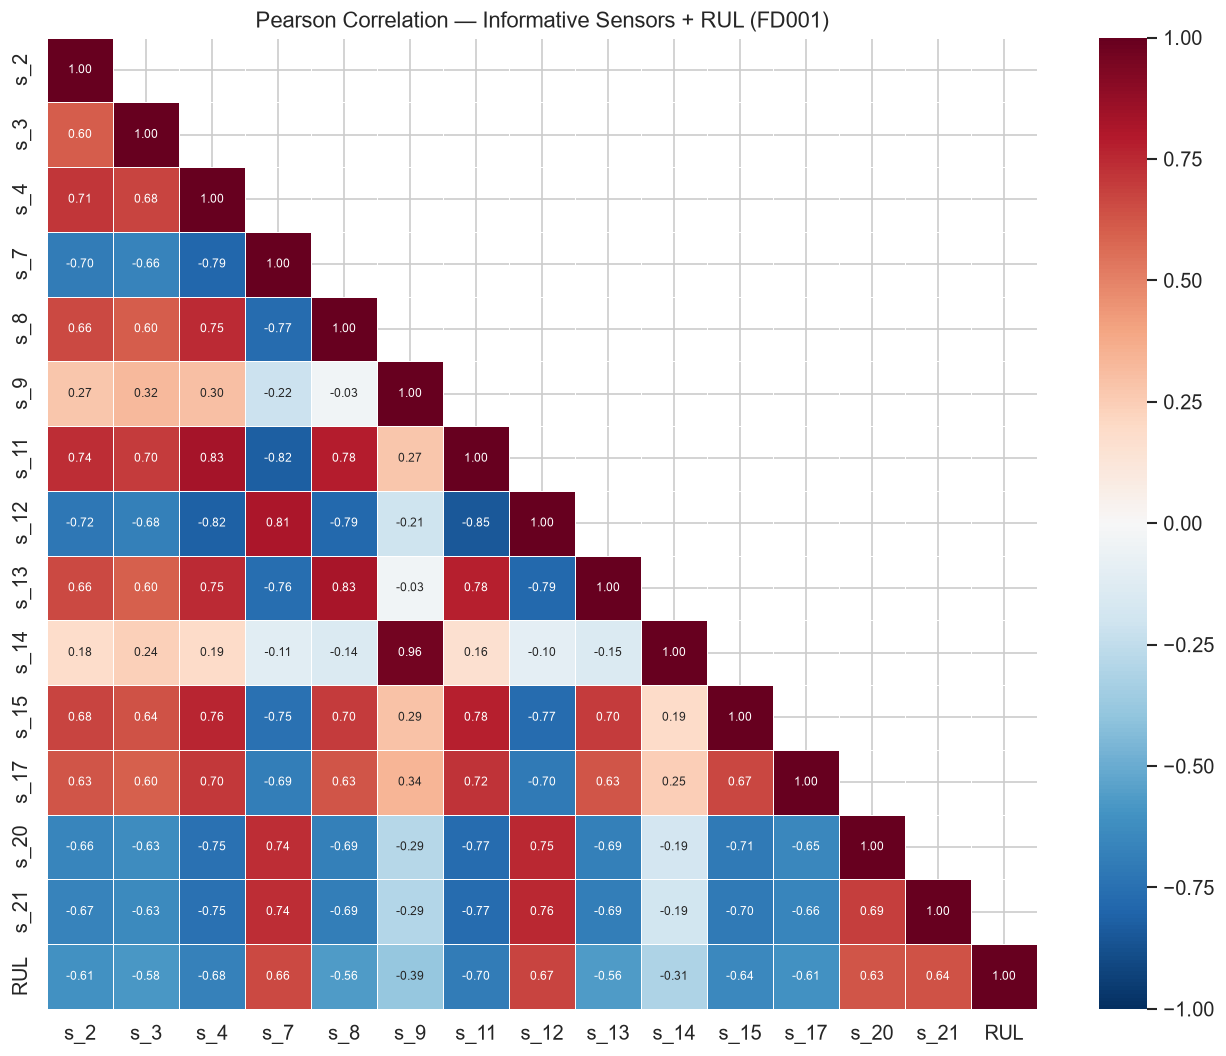

Top sensors most correlated with RUL:
  s_11   |r|=0.696  Static pressure — HPC outlet (psia)
  s_4    |r|=0.679  Total temp — LPT outlet (R)
  s_12   |r|=0.672  Fuel flow ratio (pps/psia)
  s_7    |r|=0.657  Total pressure — HPC outlet (psia)
  s_15   |r|=0.643  Bypass ratio
  s_21   |r|=0.636  LPT coolant bleed (lbm/s)
  s_20   |r|=0.629  HPT coolant bleed (lbm/s)
  s_2    |r|=0.606  Total temp — LPC outlet (R)
  s_17   |r|=0.606  Bleed enthalpy
  s_3    |r|=0.585  Total temp — HPC outlet (R)


In [13]:
corr = trains['FD001'][INFORMATIVE_SENSORS + ['RUL']].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # lower triangle only
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.4,
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Pearson Correlation — Informative Sensors + RUL (FD001)', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_04_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print('Top sensors most correlated with RUL:')
rul_corr = corr['RUL'].drop('RUL').abs().sort_values(ascending=False)
for s, v in rul_corr.head(10).items():
    print(f'  {s:5s}  |r|={v:.3f}  {SENSOR_DESC.get(s, "")}')

## 7 · RUL distribution — raw vs clipped

We cap RUL at 125 cycles. Early in engine life the RUL is very high but essentially uninformative — capping it forces the model to focus on the degradation phase.

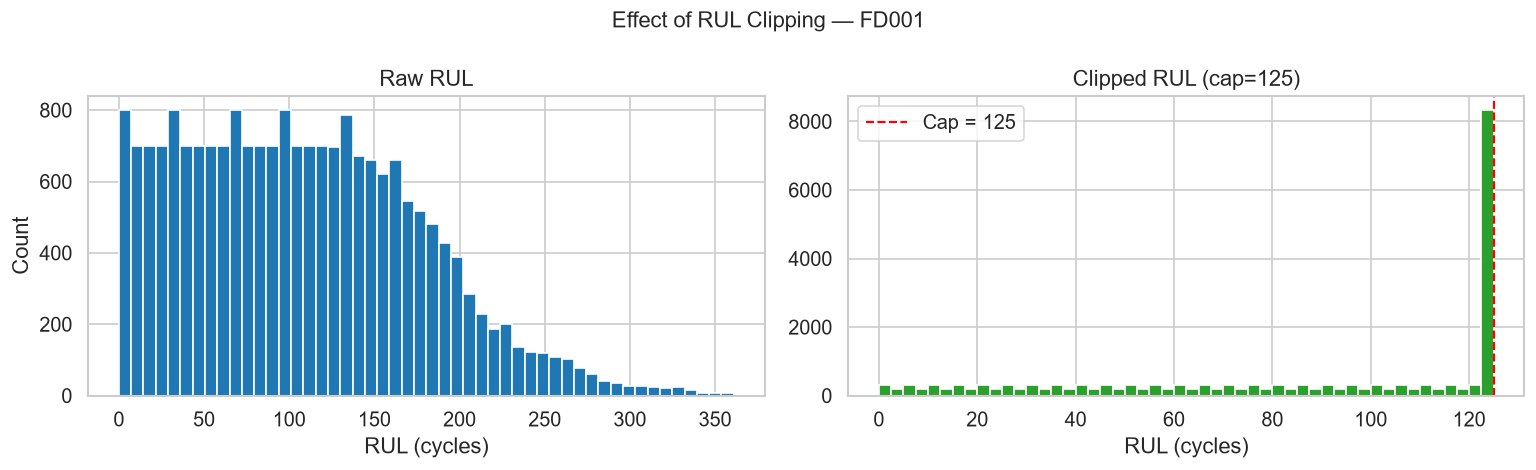

Raw RUL    — mean: 107.8, std: 68.9
Clipped    — mean: 86.8, std: 41.7


In [8]:
df = trains['FD001'].copy()
df['RUL_clipped'] = df['RUL'].clip(upper=RUL_CLIP)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df['RUL'], bins=50, color='#1f77b4', edgecolor='white')
axes[0].set_title('Raw RUL')
axes[0].set_xlabel('RUL (cycles)')
axes[0].set_ylabel('Count')

axes[1].hist(df['RUL_clipped'], bins=50, color='#2ca02c', edgecolor='white')
axes[1].axvline(RUL_CLIP, color='red', linestyle='--',
                linewidth=1.3, label=f'Cap = {RUL_CLIP}')
axes[1].set_title(f'Clipped RUL (cap={RUL_CLIP})')
axes[1].set_xlabel('RUL (cycles)')
axes[1].legend()

fig.suptitle('Effect of RUL Clipping — FD001', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_05_rul_distribution.png', bbox_inches='tight')
plt.show()

print(f'Raw RUL    — mean: {df["RUL"].mean():.1f}, std: {df["RUL"].std():.1f}')
print(f'Clipped    — mean: {df["RUL_clipped"].mean():.1f}, std: {df["RUL_clipped"].std():.1f}')

### 7b · Per-subset RUL distribution — does the cap hold across all subsets?

FD002 and FD004 have 6 operating conditions and longer engine lifetimes than FD001. Their raw RUL distributions may look different. We plot all 4 subsets side by side — both raw and clipped — to confirm that the 125-cycle cap is appropriate across the board and does not cut off genuine degradation signal in any subset.

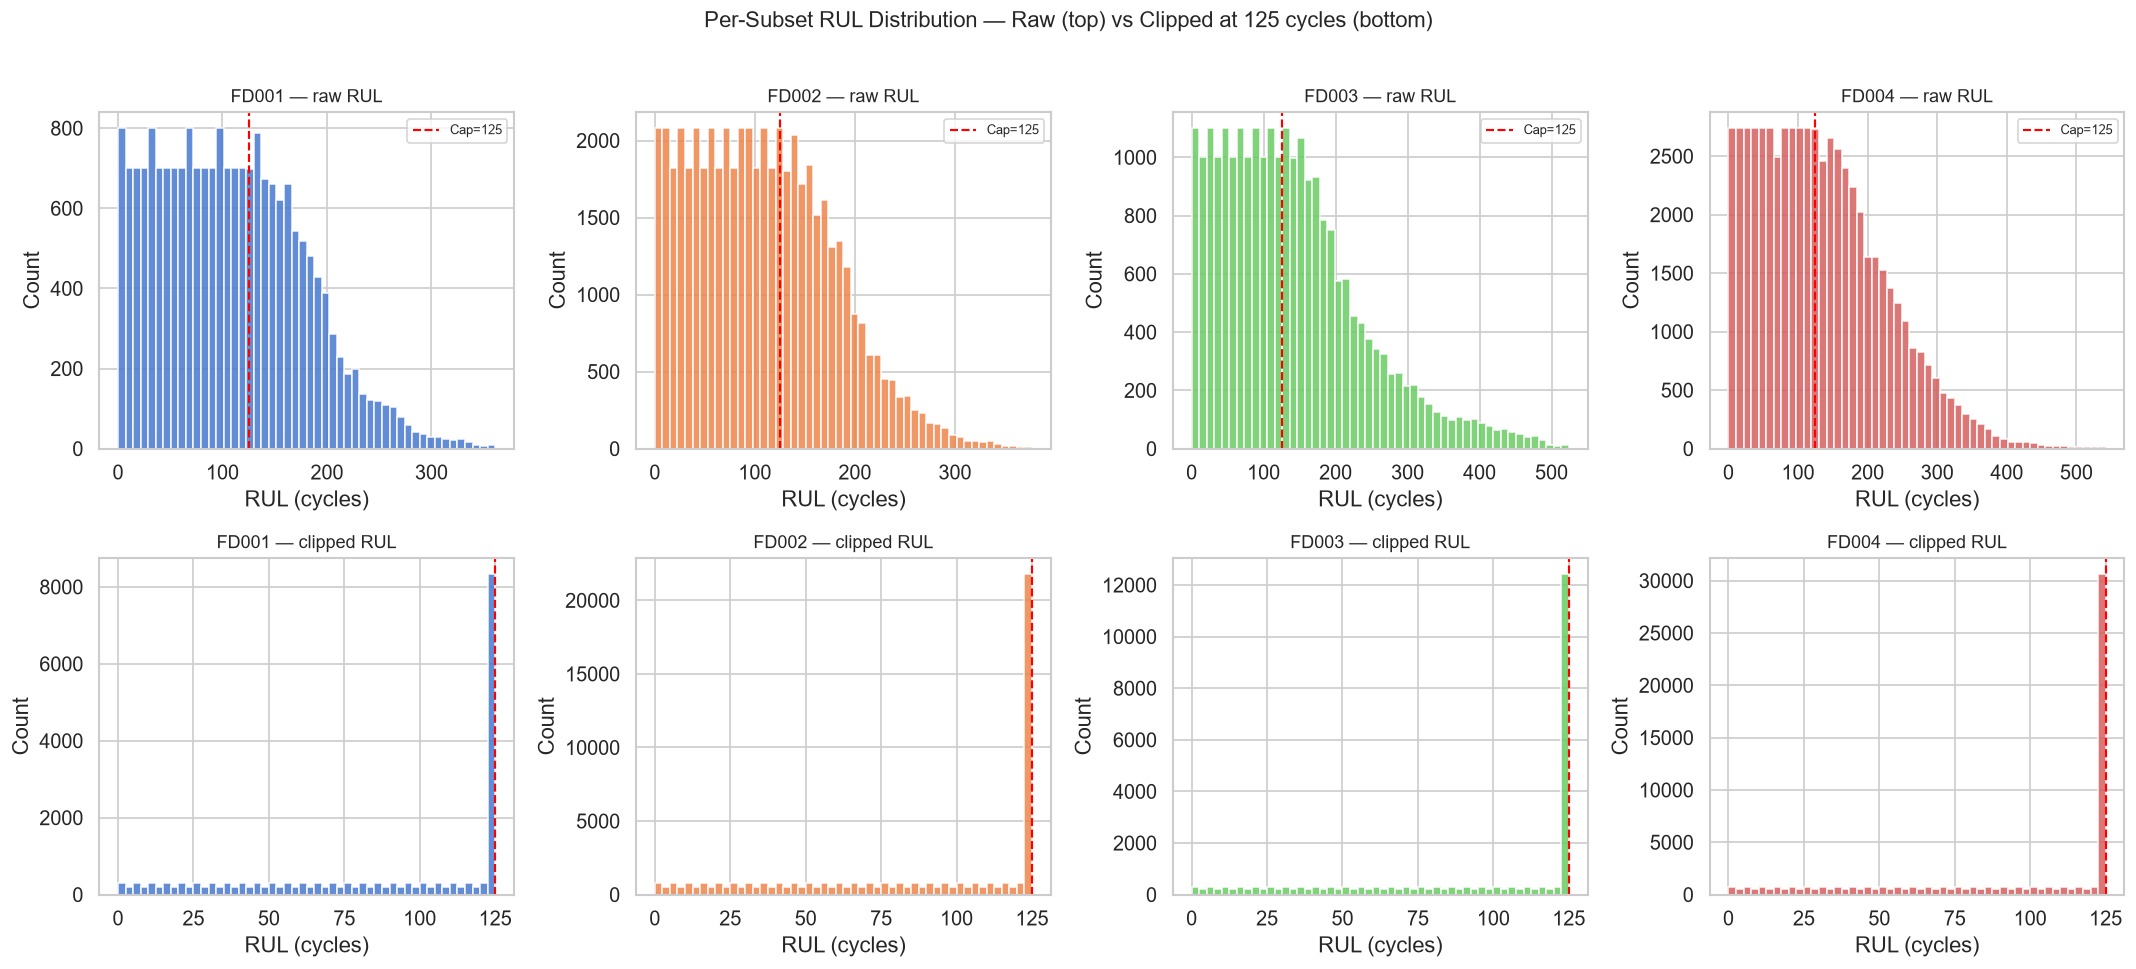

Subset     Raw mean    Raw max   Clipped mean   % rows capped
--------------------------------------------------------------
FD001         107.8        361           86.8           38.9%
FD002         108.2        377           86.9           39.1%
FD003         138.1        524           93.1           49.0%
FD004         133.3        542           93.0           48.8%

Conclusion: the 125-cycle cap is consistent across all subsets.
Rows above the cap are the flat early-life plateau — no useful degradation signal.


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
colors = sns.color_palette('muted', 4)

for col, (s, c) in enumerate(zip(SUBSETS, colors)):
    df = trains[s].copy()
    df['RUL_clipped'] = df['RUL'].clip(upper=RUL_CLIP)

    # Row 0: raw RUL
    ax_raw = axes[0][col]
    ax_raw.hist(df['RUL'], bins=50, color=c, edgecolor='white', alpha=0.85)
    ax_raw.axvline(RUL_CLIP, color='red', linestyle='--', linewidth=1.3,
                   label=f'Cap={RUL_CLIP}')
    ax_raw.set_title(f'{s} — raw RUL', fontsize=11)
    ax_raw.set_xlabel('RUL (cycles)')
    ax_raw.set_ylabel('Count')
    ax_raw.legend(fontsize=8)

    # Row 1: clipped RUL
    ax_clip = axes[1][col]
    ax_clip.hist(df['RUL_clipped'], bins=50, color=c, edgecolor='white', alpha=0.85)
    ax_clip.axvline(RUL_CLIP, color='red', linestyle='--', linewidth=1.3)
    ax_clip.set_title(f'{s} — clipped RUL', fontsize=11)
    ax_clip.set_xlabel('RUL (cycles)')
    ax_clip.set_ylabel('Count')

fig.suptitle(
    f'Per-Subset RUL Distribution — Raw (top) vs Clipped at {RUL_CLIP} cycles (bottom)',
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_05b_rul_per_subset.png', bbox_inches='tight')
plt.show()

# Summary stats per subset
print(f"{'Subset':<8} {'Raw mean':>10} {'Raw max':>10} {'Clipped mean':>14} {'% rows capped':>15}")
print('-' * 62)
for s in SUBSETS:
    df = trains[s].copy()
    df['RUL_clipped'] = df['RUL'].clip(upper=RUL_CLIP)
    pct_capped = (df['RUL'] > RUL_CLIP).mean() * 100
    print(f"{s:<8} {df['RUL'].mean():>10.1f} {df['RUL'].max():>10} "
          f"{df['RUL_clipped'].mean():>14.1f} {pct_capped:>14.1f}%")

print(f'\nConclusion: the {RUL_CLIP}-cycle cap is consistent across all subsets.')
print('Rows above the cap are the flat early-life plateau — no useful degradation signal.')

## 8 · Sliding window illustration

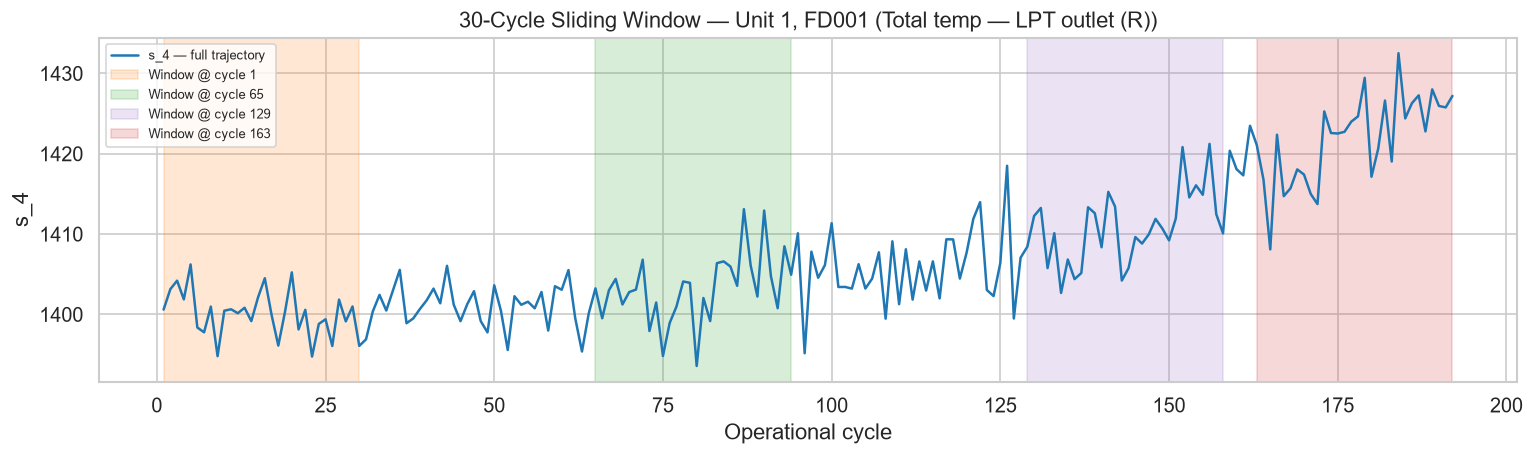

Unit 1 has 192 cycles → produces 163 windows of length 30


In [10]:
WINDOW   = 30
SENSOR   = 's_4'   # exhaust temperature — strong degradation signal
unit1    = (trains['FD001'][trains['FD001']['unit_id'] == 1]
            .sort_values('cycle').reset_index(drop=True))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(unit1['cycle'], unit1[SENSOR], color='#1f77b4',
        linewidth=1.5, label=f'{SENSOR} — full trajectory')

starts = [0, len(unit1)//3, 2*len(unit1)//3, len(unit1)-WINDOW]
wcols  = ['#ff7f0e', '#2ca02c', '#9467bd', '#d62728']
for ws, wc in zip(starts, wcols):
    win = unit1.iloc[ws:ws + WINDOW]
    ax.axvspan(win['cycle'].iloc[0], win['cycle'].iloc[-1],
               alpha=0.18, color=wc,
               label=f'Window @ cycle {win["cycle"].iloc[0]}')

ax.set_xlabel('Operational cycle')
ax.set_ylabel(f'{SENSOR}')
ax.set_title(f'30-Cycle Sliding Window — Unit 1, FD001 ({SENSOR_DESC[SENSOR]})')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_06_sliding_window.png', bbox_inches='tight')
plt.show()

n_windows = len(unit1) - WINDOW + 1
print(f'Unit 1 has {len(unit1)} cycles → produces {n_windows} windows of length {WINDOW}')

## 9 · Operational condition analysis

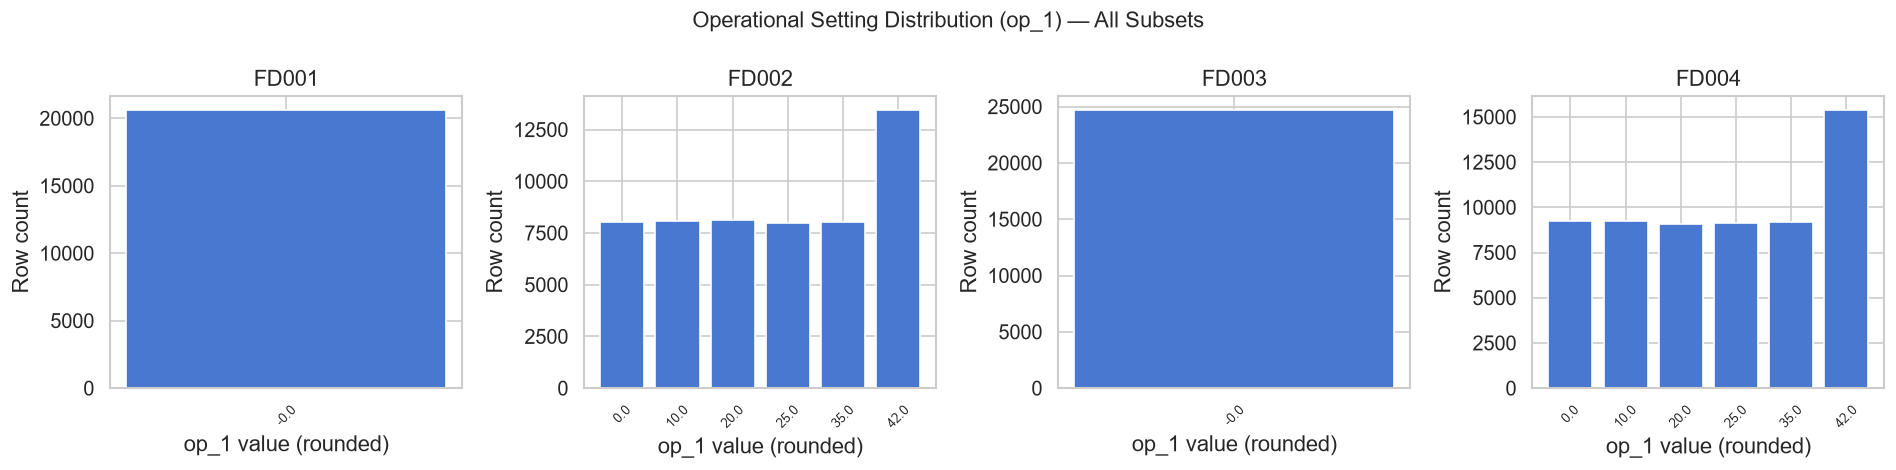

FD001/FD003 → 1 operating condition  (easier to normalise)
FD002/FD004 → 6 operating conditions (must normalise per regime to avoid bias)


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, s in zip(axes, SUBSETS):
    op1 = trains[s]['op_1'].round(1).value_counts().sort_index()
    ax.bar(op1.index.astype(str), op1.values, edgecolor='white')
    ax.set_title(s)
    ax.set_xlabel('op_1 value (rounded)')
    ax.set_ylabel('Row count')
    ax.tick_params(axis='x', rotation=45, labelsize=8)

fig.suptitle('Operational Setting Distribution (op_1) — All Subsets', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_07_op_conditions.png', bbox_inches='tight')
plt.show()
print('FD001/FD003 → 1 operating condition  (easier to normalise)')
print('FD002/FD004 → 6 operating conditions (must normalise per regime to avoid bias)')

## 10 · Cross-subset degradation trends

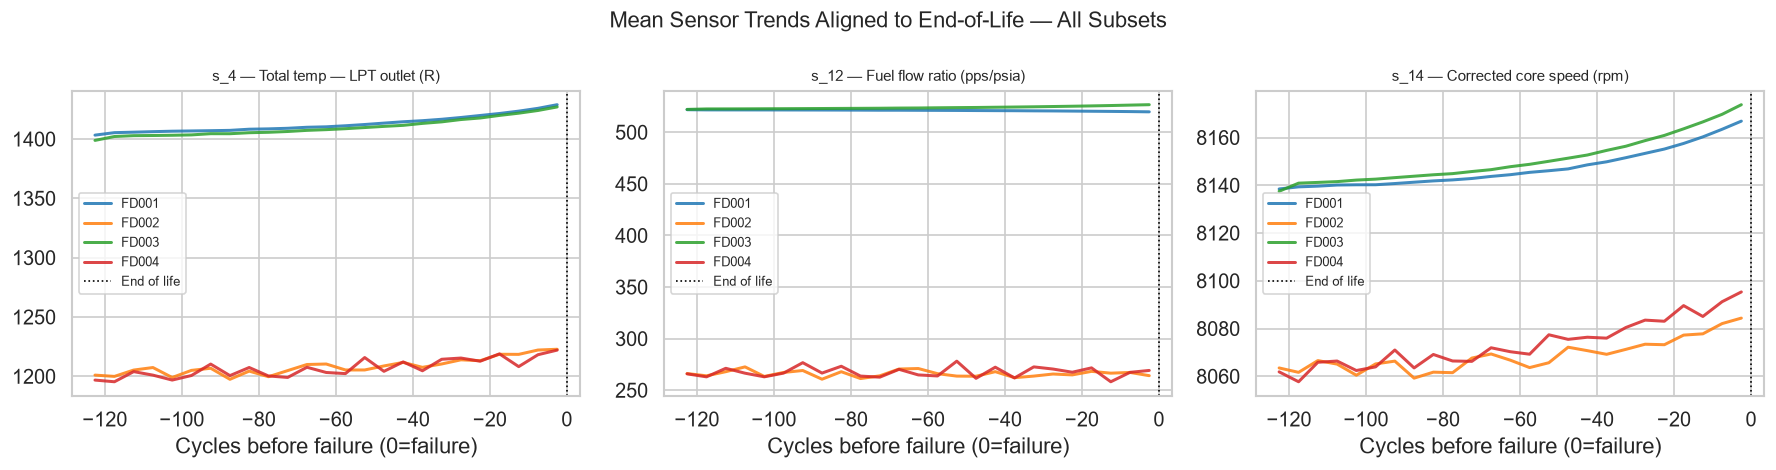

In [12]:
FOCUS  = ['s_4', 's_12', 's_14']   # exhaust temp, fuel flow, core speed
scols  = {'FD001':'#1f77b4','FD002':'#ff7f0e','FD003':'#2ca02c','FD004':'#d62728'}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, sensor in zip(axes, FOCUS):
    for s in SUBSETS:
        df = trains[s].copy()
        df['rul_neg'] = -df['RUL'].clip(upper=RUL_CLIP)
        df['rul_bin'] = pd.cut(df['rul_neg'], bins=25)
        trend = df.groupby('rul_bin')[sensor].mean()
        mids  = [iv.mid for iv in trend.index]
        ax.plot(mids, trend.values, label=s, color=scols[s], lw=1.8, alpha=0.85)
    ax.axvline(0, color='black', linestyle=':', lw=1, label='End of life')
    ax.set_title(f'{sensor} — {SENSOR_DESC.get(sensor,"")[:28]}', fontsize=9)
    ax.set_xlabel('Cycles before failure (0=failure)')
    ax.legend(fontsize=8)

fig.suptitle('Mean Sensor Trends Aligned to End-of-Life — All Subsets', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / 'eda_08_cross_subset_trends.png', bbox_inches='tight')
plt.show()